In [21]:
# ============================================================
# MENGARSIPKAN SELURUH HASIL SIMULASI
# ============================================================

import shutil
import os
from google.colab import files

folder_output = "/content/hasil_simulasi"
file_zip = "/content/hasil_uts_pemodelan_simulasi_faris.zip"

# Membuat arsip ZIP
shutil.make_archive(
    "/content/hasil_uts_pemodelan_simulasi_faris",
    "zip",
    folder_output
)

# Memeriksa ukuran ZIP
ukuran_zip = os.path.getsize(file_zip) / (1024 * 1024)

print("=" * 70)
print("ARSIP HASIL SIMULASI BERHASIL DIBUAT")
print("=" * 70)

print("Nama file :", os.path.basename(file_zip))
print(f"Ukuran    : {ukuran_zip:.2f} MB")

# Mengunduh ZIP
files.download(file_zip)

ARSIP HASIL SIMULASI BERHASIL DIBUAT
Nama file : hasil_uts_pemodelan_simulasi_faris.zip
Ukuran    : 2.87 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:
# ============================================================
# MENYIMPAN SELURUH GRAFIK SIMULASI DAN SENSITIVITAS
# ============================================================

import os
import matplotlib.pyplot as plt

folder_grafik = "/content/hasil_simulasi/visualisasi"
os.makedirs(folder_grafik, exist_ok=True)

# ============================================================
# A. VISUALISASI SIMULASI UTAMA
# ============================================================

# 1. Tren Persediaan
plt.figure(figsize=(14, 6))

for lead_time, hasil in hasil_simulasi_semua.items():
    plt.plot(
        hasil["Date"],
        hasil["Persediaan_Akhir"],
        label=f"Lead Time {lead_time} Hari",
        linewidth=1
    )

plt.title("Tren Persediaan Berdasarkan Variasi Lead Time")
plt.xlabel("Tanggal")
plt.ylabel("Persediaan Akhir")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{folder_grafik}/06_tren_persediaan_uji.png", dpi=300)
plt.close()


# 2. Perbandingan Lost Sales
plt.figure(figsize=(9, 5))

plt.bar(
    ringkasan_simulasi["Lead_Time"].astype(str),
    ringkasan_simulasi["Lost_Sales"]
)

plt.title("Perbandingan Lost Sales Berdasarkan Lead Time")
plt.xlabel("Lead Time (Hari)")
plt.ylabel("Total Lost Sales")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(f"{folder_grafik}/07_perbandingan_lost_sales_uji.png", dpi=300)
plt.close()


# 3. Perbandingan Fill Rate
plt.figure(figsize=(9, 5))

plt.bar(
    ringkasan_simulasi["Lead_Time"].astype(str),
    ringkasan_simulasi["Fill_Rate_Persen"]
)

plt.title("Perbandingan Fill Rate Berdasarkan Lead Time")
plt.xlabel("Lead Time (Hari)")
plt.ylabel("Fill Rate (%)")
plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(f"{folder_grafik}/08_perbandingan_fill_rate_uji.png", dpi=300)
plt.close()


# 4. Rata-rata Persediaan
plt.figure(figsize=(9, 5))

plt.bar(
    ringkasan_simulasi["Lead_Time"].astype(str),
    ringkasan_simulasi["Rata_Rata_Persediaan"]
)

plt.title("Perbandingan Rata-rata Persediaan")
plt.xlabel("Lead Time (Hari)")
plt.ylabel("Rata-rata Persediaan")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(f"{folder_grafik}/09_rata_rata_persediaan_uji.png", dpi=300)
plt.close()


# 5. Permintaan dan Penjualan
plt.figure(figsize=(14, 6))

plt.plot(
    data_pengujian["Date"],
    data_pengujian["Units Sold"],
    label="Demand",
    alpha=0.6
)

plt.plot(
    hasil_simulasi_semua[1]["Date"],
    hasil_simulasi_semua[1]["Actual_Sales"],
    label="Actual Sales (LT 1)",
    alpha=0.8
)

plt.title("Perbandingan Demand dan Penjualan Aktual")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah Unit")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{folder_grafik}/10_permintaan_penjualan_uji.png", dpi=300)
plt.close()


# ============================================================
# B. VISUALISASI ANALISIS SENSITIVITAS
# ============================================================

urutan_skenario = ["Rendah", "Baseline", "Tinggi"]

# 6. Sensitivitas Lost Sales
plt.figure(figsize=(10, 6))

for lead_time in [1, 2, 3]:
    data_plot = (
        tabel_sensitivitas[
            tabel_sensitivitas["Lead_Time"] == lead_time
        ]
        .set_index("Skenario")
        .loc[urutan_skenario]
    )

    plt.plot(
        urutan_skenario,
        data_plot["Lost_Sales"],
        marker="o",
        linewidth=2,
        label=f"Lead Time {lead_time} Hari"
    )

plt.title("Sensitivitas Safety Stock terhadap Lost Sales")
plt.xlabel("Skenario Safety Stock")
plt.ylabel("Total Lost Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{folder_grafik}/11_sensitivitas_lost_sales.png", dpi=300)
plt.close()


# 7. Sensitivitas Fill Rate
plt.figure(figsize=(10, 6))

for lead_time in [1, 2, 3]:
    data_plot = (
        tabel_sensitivitas[
            tabel_sensitivitas["Lead_Time"] == lead_time
        ]
        .set_index("Skenario")
        .loc[urutan_skenario]
    )

    plt.plot(
        urutan_skenario,
        data_plot["Fill_Rate_Persen"],
        marker="o",
        linewidth=2,
        label=f"Lead Time {lead_time} Hari"
    )

plt.title("Sensitivitas Safety Stock terhadap Fill Rate")
plt.xlabel("Skenario Safety Stock")
plt.ylabel("Fill Rate (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{folder_grafik}/12_sensitivitas_fill_rate.png", dpi=300)
plt.close()


# 8. Sensitivitas Rata-rata Persediaan
plt.figure(figsize=(10, 6))

for lead_time in [1, 2, 3]:
    data_plot = (
        tabel_sensitivitas[
            tabel_sensitivitas["Lead_Time"] == lead_time
        ]
        .set_index("Skenario")
        .loc[urutan_skenario]
    )

    plt.plot(
        urutan_skenario,
        data_plot["Rata_Rata_Persediaan"],
        marker="o",
        linewidth=2,
        label=f"Lead Time {lead_time} Hari"
    )

plt.title("Sensitivitas Safety Stock terhadap Rata-rata Persediaan")
plt.xlabel("Skenario Safety Stock")
plt.ylabel("Rata-rata Persediaan")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{folder_grafik}/13_sensitivitas_rata_rata_persediaan.png", dpi=300)
plt.close()


# 9. Sensitivitas Hari Stockout
plt.figure(figsize=(10, 6))

for lead_time in [1, 2, 3]:
    data_plot = (
        tabel_sensitivitas[
            tabel_sensitivitas["Lead_Time"] == lead_time
        ]
        .set_index("Skenario")
        .loc[urutan_skenario]
    )

    plt.plot(
        urutan_skenario,
        data_plot["Hari_Stockout"],
        marker="o",
        linewidth=2,
        label=f"Lead Time {lead_time} Hari"
    )

plt.title("Sensitivitas Safety Stock terhadap Hari Stockout")
plt.xlabel("Skenario Safety Stock")
plt.ylabel("Jumlah Hari Stockout")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{folder_grafik}/14_sensitivitas_hari_stockout.png", dpi=300)
plt.close()


# ============================================================
# C. MENAMPILKAN DAFTAR GRAFIK
# ============================================================

print("=" * 75)
print("DAFTAR GRAFIK YANG BERHASIL DISIMPAN")
print("=" * 75)

for nama_file in sorted(os.listdir(folder_grafik)):
    ukuran = os.path.getsize(
        os.path.join(folder_grafik, nama_file)
    ) / 1024

    print(f"{nama_file:<55} {ukuran:>8.2f} KB")

print("\nTOTAL GRAFIK:", len(os.listdir(folder_grafik)))
print("SELURUH GRAFIK BERHASIL DISIMPAN!")

DAFTAR GRAFIK YANG BERHASIL DISIMPAN
06_tren_persediaan_uji.png                               1295.47 KB
07_perbandingan_lost_sales_uji.png                         80.16 KB
08_perbandingan_fill_rate_uji.png                          66.71 KB
09_rata_rata_persediaan_uji.png                            79.40 KB
10_permintaan_penjualan_uji.png                           781.34 KB
11_sensitivitas_lost_sales.png                            228.35 KB
12_sensitivitas_fill_rate.png                             194.08 KB
13_sensitivitas_rata_rata_persediaan.png                  198.48 KB
14_sensitivitas_hari_stockout.png                         231.76 KB

TOTAL GRAFIK: 9
SELURUH GRAFIK BERHASIL DISIMPAN!


In [19]:
# ============================================================
# MENYIMPAN SELURUH HASIL SIMULASI
# ============================================================

import os

folder_output = "/content/hasil_simulasi"

os.makedirs(folder_output, exist_ok=True)

# ------------------------------------------------------------
# 1. MENYIMPAN PARAMETER KALIBRASI
# ------------------------------------------------------------

parameter_kalibrasi.to_csv(
    f"{folder_output}/parameter_kalibrasi.csv",
    index=False
)

# ------------------------------------------------------------
# 2. MENYIMPAN HASIL SIMULASI UTAMA
# ------------------------------------------------------------

for lead_time, hasil in hasil_simulasi_semua.items():

    hasil.to_csv(
        f"{folder_output}/hasil_uji_lead_time_{lead_time}_hari.csv",
        index=False
    )

# ------------------------------------------------------------
# 3. MENYIMPAN RINGKASAN SIMULASI
# ------------------------------------------------------------

ringkasan_simulasi.to_csv(
    f"{folder_output}/ringkasan_uji_simulasi.csv",
    index=False
)

# ------------------------------------------------------------
# 4. MENYIMPAN HASIL ANALISIS SENSITIVITAS
# ------------------------------------------------------------

tabel_sensitivitas.to_csv(
    f"{folder_output}/hasil_analisis_sensitivitas.csv",
    index=False
)

# ------------------------------------------------------------
# 5. MENYIMPAN DETAIL 9 SKENARIO SENSITIVITAS
# ------------------------------------------------------------

for (lead_time, skenario), hasil in detail_sensitivitas.items():

    nama_file = (
        f"detail_LT{lead_time}_{skenario.lower()}.csv"
    )

    hasil.to_csv(
        f"{folder_output}/{nama_file}",
        index=False
    )

# ------------------------------------------------------------
# 6. MENAMPILKAN DAFTAR FILE
# ------------------------------------------------------------

print("=" * 70)
print("DAFTAR HASIL SIMULASI YANG BERHASIL DISIMPAN")
print("=" * 70)

for nama_file in sorted(os.listdir(folder_output)):

    ukuran = os.path.getsize(
        f"{folder_output}/{nama_file}"
    ) / 1024

    print(f"{nama_file:<50} {ukuran:>8.2f} KB")

print("\nSELURUH HASIL SIMULASI BERHASIL DISIMPAN!")

DAFTAR HASIL SIMULASI YANG BERHASIL DISIMPAN
detail_LT1_baseline.csv                               16.59 KB
detail_LT1_rendah.csv                                 16.51 KB
detail_LT1_tinggi.csv                                 16.63 KB
detail_LT2_baseline.csv                               17.03 KB
detail_LT2_rendah.csv                                 16.99 KB
detail_LT2_tinggi.csv                                 17.05 KB
detail_LT3_baseline.csv                               17.24 KB
detail_LT3_rendah.csv                                 17.21 KB
detail_LT3_tinggi.csv                                 17.26 KB
hasil_analisis_sensitivitas.csv                        0.68 KB
hasil_uji_lead_time_1_hari.csv                        16.59 KB
hasil_uji_lead_time_2_hari.csv                        17.03 KB
hasil_uji_lead_time_3_hari.csv                        17.24 KB
parameter_kalibrasi.csv                                0.25 KB
ringkasan_uji_simulasi.csv                             0.32 KB

SELURUH H

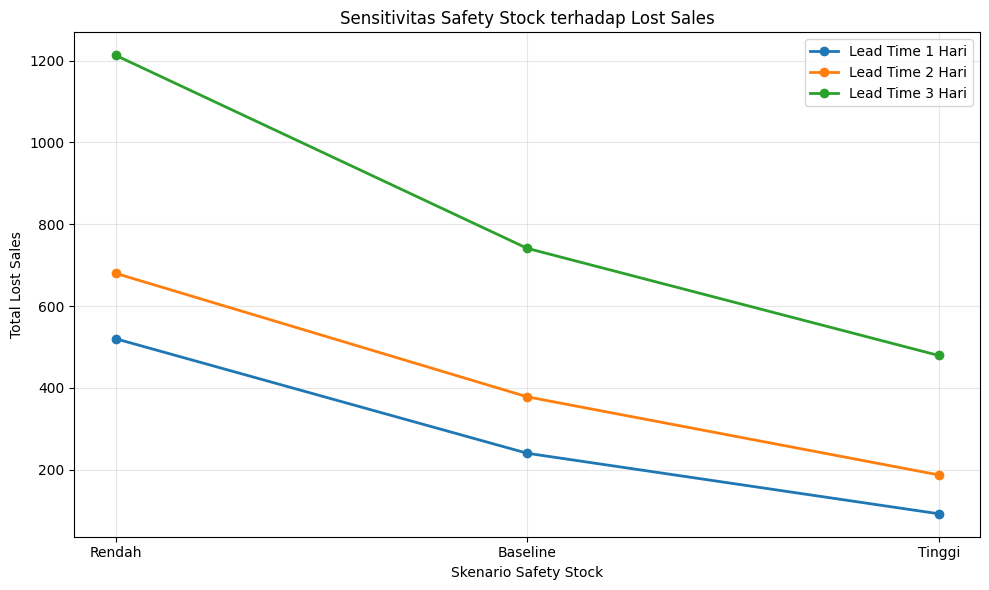

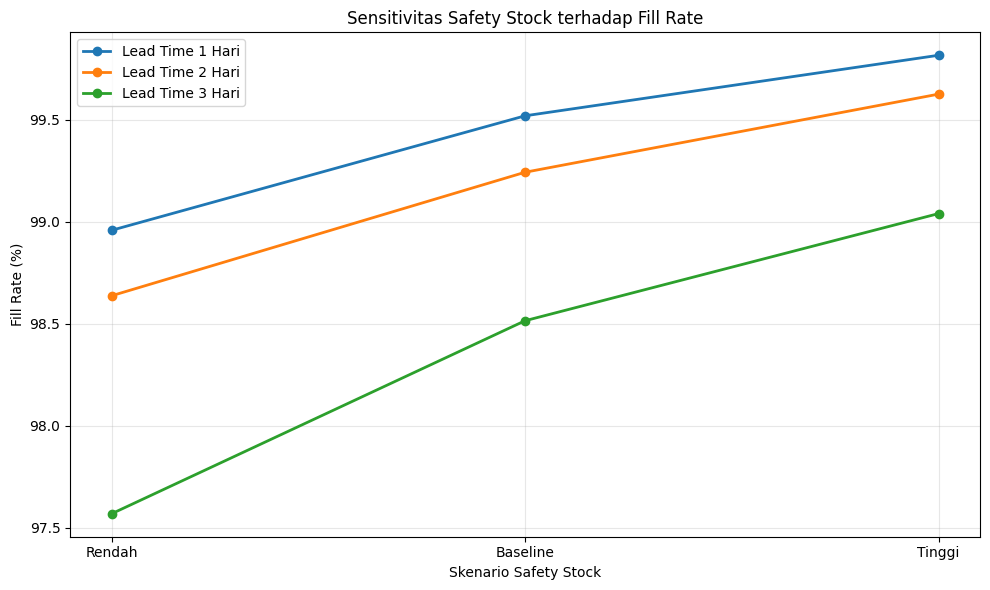

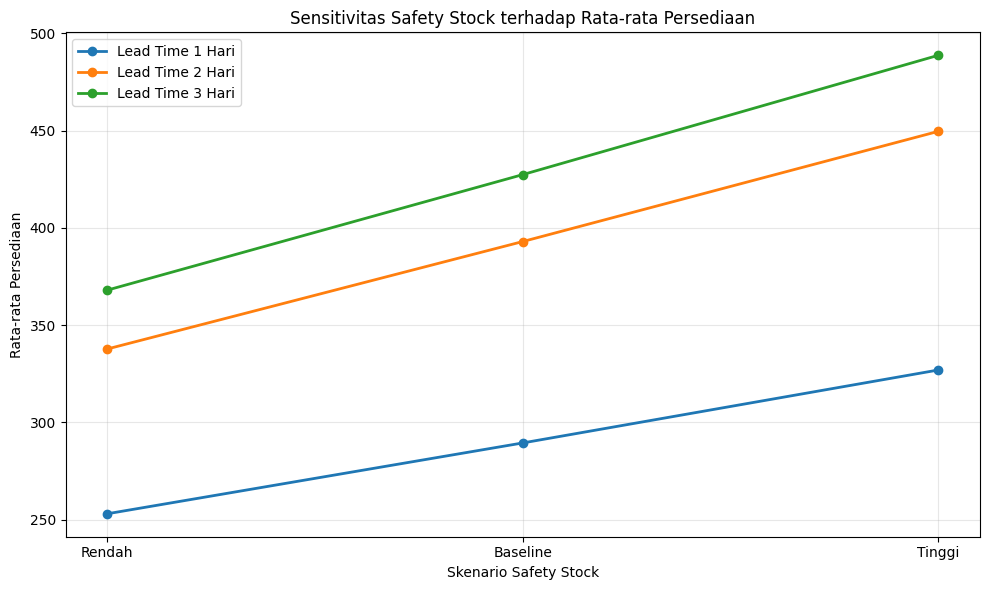

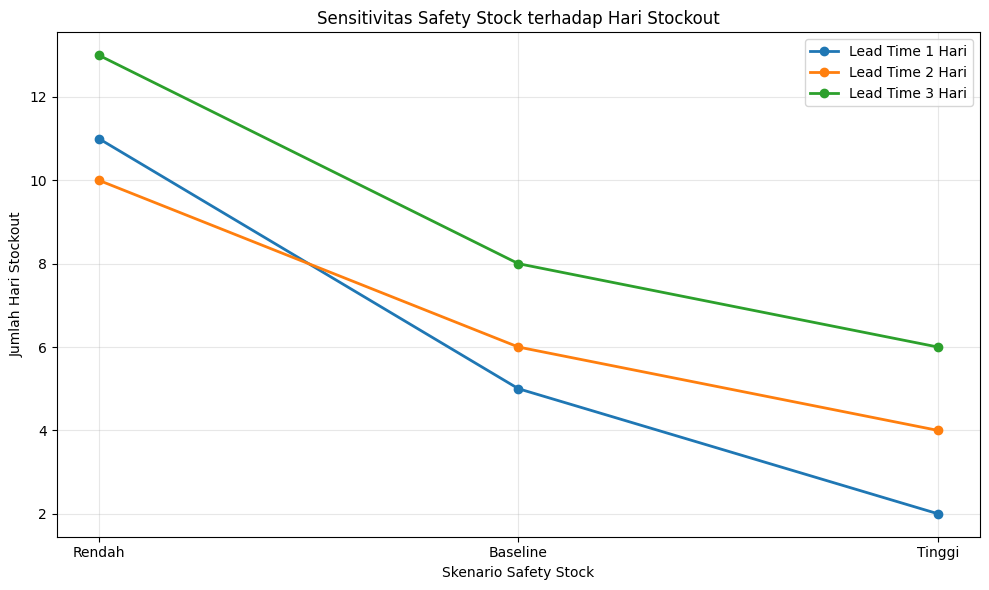

SELURUH VISUALISASI SENSITIVITAS BERHASIL DIBUAT!


In [18]:
# ============================================================
# VISUALISASI ANALISIS SENSITIVITAS
# ============================================================

urutan_skenario = ["Rendah", "Baseline", "Tinggi"]

# ------------------------------------------------------------
# 1. PERBANDINGAN LOST SALES
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

for lead_time in [1, 2, 3]:

    data_plot = tabel_sensitivitas[
        tabel_sensitivitas["Lead_Time"] == lead_time
    ].set_index("Skenario").loc[urutan_skenario]

    plt.plot(
        urutan_skenario,
        data_plot["Lost_Sales"],
        marker="o",
        linewidth=2,
        label=f"Lead Time {lead_time} Hari"
    )

plt.title("Sensitivitas Safety Stock terhadap Lost Sales")
plt.xlabel("Skenario Safety Stock")
plt.ylabel("Total Lost Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. PERBANDINGAN FILL RATE
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

for lead_time in [1, 2, 3]:

    data_plot = tabel_sensitivitas[
        tabel_sensitivitas["Lead_Time"] == lead_time
    ].set_index("Skenario").loc[urutan_skenario]

    plt.plot(
        urutan_skenario,
        data_plot["Fill_Rate_Persen"],
        marker="o",
        linewidth=2,
        label=f"Lead Time {lead_time} Hari"
    )

plt.title("Sensitivitas Safety Stock terhadap Fill Rate")
plt.xlabel("Skenario Safety Stock")
plt.ylabel("Fill Rate (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. PERBANDINGAN RATA-RATA PERSEDIAAN
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

for lead_time in [1, 2, 3]:

    data_plot = tabel_sensitivitas[
        tabel_sensitivitas["Lead_Time"] == lead_time
    ].set_index("Skenario").loc[urutan_skenario]

    plt.plot(
        urutan_skenario,
        data_plot["Rata_Rata_Persediaan"],
        marker="o",
        linewidth=2,
        label=f"Lead Time {lead_time} Hari"
    )

plt.title("Sensitivitas Safety Stock terhadap Rata-rata Persediaan")
plt.xlabel("Skenario Safety Stock")
plt.ylabel("Rata-rata Persediaan")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. PERBANDINGAN HARI STOCKOUT
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

for lead_time in [1, 2, 3]:

    data_plot = tabel_sensitivitas[
        tabel_sensitivitas["Lead_Time"] == lead_time
    ].set_index("Skenario").loc[urutan_skenario]

    plt.plot(
        urutan_skenario,
        data_plot["Hari_Stockout"],
        marker="o",
        linewidth=2,
        label=f"Lead Time {lead_time} Hari"
    )

plt.title("Sensitivitas Safety Stock terhadap Hari Stockout")
plt.xlabel("Skenario Safety Stock")
plt.ylabel("Jumlah Hari Stockout")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


print("SELURUH VISUALISASI SENSITIVITAS BERHASIL DIBUAT!")

In [17]:
# ============================================================
# VALIDASI HASIL ANALISIS SENSITIVITAS
# ============================================================

print("=" * 75)
print("VALIDASI HASIL ANALISIS SENSITIVITAS")
print("=" * 75)

semua_lulus = True

for (lead_time, skenario), hasil in detail_sensitivitas.items():

    # Validasi keseimbangan persediaan
    saldo_hitung = (
        hasil["Persediaan_Awal_Hari"]
        + hasil["Arrival_Quantity"]
        - hasil["Actual_Sales"]
    )

    error_saldo = (
        saldo_hitung - hasil["Persediaan_Akhir"]
    ).abs().sum()

    # Validasi keseimbangan demand
    error_demand = (
        hasil["Demand"].sum()
        - hasil["Actual_Sales"].sum()
        - hasil["Lost_Sales"].sum()
    )

    # Validasi jumlah data
    jumlah_data = len(hasil)

    # Validasi nilai negatif
    kolom_numerik = [
        "Persediaan_Awal_Hari",
        "Arrival_Quantity",
        "Persediaan_Tersedia",
        "Actual_Sales",
        "Lost_Sales",
        "Persediaan_Akhir",
        "Outstanding_Order",
        "Order_Quantity"
    ]

    ada_nilai_negatif = (
        hasil[kolom_numerik] < 0
    ).any().any()

    lulus = (
        error_saldo == 0
        and error_demand == 0
        and jumlah_data == 366
        and not ada_nilai_negatif
    )

    if not lulus:
        semua_lulus = False

    print(f"\n[LEAD TIME {lead_time} HARI - {skenario.upper()}]")
    print("-" * 65)
    print(f"Jumlah data 366 hari       : {'LULUS' if jumlah_data == 366 else 'GAGAL'}")
    print(f"Keseimbangan persediaan    : {'LULUS' if error_saldo == 0 else 'GAGAL'} | Error: {error_saldo}")
    print(f"Keseimbangan demand        : {'LULUS' if error_demand == 0 else 'GAGAL'} | Error: {error_demand}")
    print(f"Tidak ada nilai negatif    : {'LULUS' if not ada_nilai_negatif else 'GAGAL'}")


# Validasi kecocokan baseline dengan simulasi utama
print("\n" + "=" * 75)
print("VALIDASI KECOCOKAN BASELINE")
print("=" * 75)

for lead_time in [1, 2, 3]:

    utama = hasil_simulasi_semua[lead_time]

    baseline = detail_sensitivitas[
        (lead_time, "Baseline")
    ]

    kolom_perbandingan = [
        "Lost_Sales",
        "Actual_Sales",
        "Order_Quantity",
        "Persediaan_Akhir"
    ]

    cocok = True

    for kolom in kolom_perbandingan:
        if not utama[kolom].equals(baseline[kolom]):
            cocok = False

    print(
        f"Lead Time {lead_time} Hari: "
        f"{'LULUS' if cocok else 'GAGAL'}"
    )

    if not cocok:
        semua_lulus = False


print("\n" + "=" * 75)

if semua_lulus:
    print("SELURUH VALIDASI ANALISIS SENSITIVITAS LULUS!")
else:
    print("TERDAPAT VALIDASI YANG BELUM LULUS!")

VALIDASI HASIL ANALISIS SENSITIVITAS

[LEAD TIME 1 HARI - RENDAH]
-----------------------------------------------------------------
Jumlah data 366 hari       : LULUS
Keseimbangan persediaan    : LULUS | Error: 0
Keseimbangan demand        : LULUS | Error: 0
Tidak ada nilai negatif    : LULUS

[LEAD TIME 1 HARI - BASELINE]
-----------------------------------------------------------------
Jumlah data 366 hari       : LULUS
Keseimbangan persediaan    : LULUS | Error: 0
Keseimbangan demand        : LULUS | Error: 0
Tidak ada nilai negatif    : LULUS

[LEAD TIME 1 HARI - TINGGI]
-----------------------------------------------------------------
Jumlah data 366 hari       : LULUS
Keseimbangan persediaan    : LULUS | Error: 0
Keseimbangan demand        : LULUS | Error: 0
Tidak ada nilai negatif    : LULUS

[LEAD TIME 2 HARI - RENDAH]
-----------------------------------------------------------------
Jumlah data 366 hari       : LULUS
Keseimbangan persediaan    : LULUS | Error: 0
Keseimbangan d

In [16]:
# ============================================================
# ANALISIS SENSITIVITAS KEBIJAKAN PERSEDIAAN
# ============================================================

skenario_safety_stock = {
    "Rendah": 0.80,
    "Baseline": 1.00,
    "Tinggi": 1.20
}

hasil_sensitivitas = []

detail_sensitivitas = {}

for _, parameter in parameter_kalibrasi.iterrows():

    lead_time = int(parameter["Lead_Time"])

    safety_stock_dasar = int(parameter["Safety_Stock"])
    rata_demand_lt = parameter["Rata_Rata_Demand_Lead_Time"]

    rop_dasar = int(parameter["Reorder_Point"])
    target_dasar = int(parameter["Target_Persediaan"])

    for nama_skenario, faktor in skenario_safety_stock.items():

        # Menghitung Safety Stock baru
        safety_stock = math.ceil(
            safety_stock_dasar * faktor
        )

        # Menghitung ROP baru
        rop = math.ceil(
            rata_demand_lt + safety_stock
        )

        # Target persediaan mengikuti perubahan ROP
        target = target_dasar + (rop - rop_dasar)

        # Menjalankan simulasi
        hasil = jalankan_simulasi(
            data=data_pengujian,
            lead_time=lead_time,
            reorder_point=rop,
            target_persediaan=target
        )

        # Menghitung indikator kinerja
        total_demand = hasil["Demand"].sum()
        total_sales = hasil["Actual_Sales"].sum()
        lost_sales = hasil["Lost_Sales"].sum()

        fill_rate = (
            total_sales / total_demand * 100
            if total_demand > 0 else 0
        )

        rata_persediaan = (
            hasil["Persediaan_Akhir"].mean()
        )

        hari_stockout = (
            hasil["Lost_Sales"] > 0
        ).sum()

        # Menyimpan hasil
        hasil_sensitivitas.append({

            "Lead_Time": lead_time,
            "Skenario": nama_skenario,
            "Safety_Stock": safety_stock,
            "ROP": rop,
            "Target_Persediaan": target,
            "Lost_Sales": lost_sales,
            "Fill_Rate_Persen": fill_rate,
            "Rata_Rata_Persediaan": rata_persediaan,
            "Hari_Stockout": hari_stockout

        })

        detail_sensitivitas[
            (lead_time, nama_skenario)
        ] = hasil


# Membuat DataFrame hasil sensitivitas
tabel_sensitivitas = pd.DataFrame(hasil_sensitivitas)

print("=" * 85)
print("HASIL ANALISIS SENSITIVITAS PERSEDIAAN")
print("=" * 85)

display(tabel_sensitivitas.round(2))

HASIL ANALISIS SENSITIVITAS PERSEDIAAN


,Lead_Time,Skenario,Safety_Stock,ROP,Target_Persediaan,Lost_Sales,Fill_Rate_Persen,Rata_Rata_Persediaan,Hari_Stockout
0,1,Rendah,149,285,420,520,98.96,253.07,11
1,1,Baseline,186,322,457,240,99.52,289.48,5
2,1,Tinggi,224,360,495,92,99.82,326.98,2
3,2,Rendah,232,503,639,680,98.64,337.74,10
4,2,Baseline,289,560,696,378,99.24,392.97,6
5,2,Tinggi,347,618,754,187,99.63,449.61,4
6,3,Rendah,256,663,799,1213,97.57,367.98,13
7,3,Baseline,320,727,863,741,98.51,427.37,8
8,3,Tinggi,384,791,927,479,99.04,488.70,6


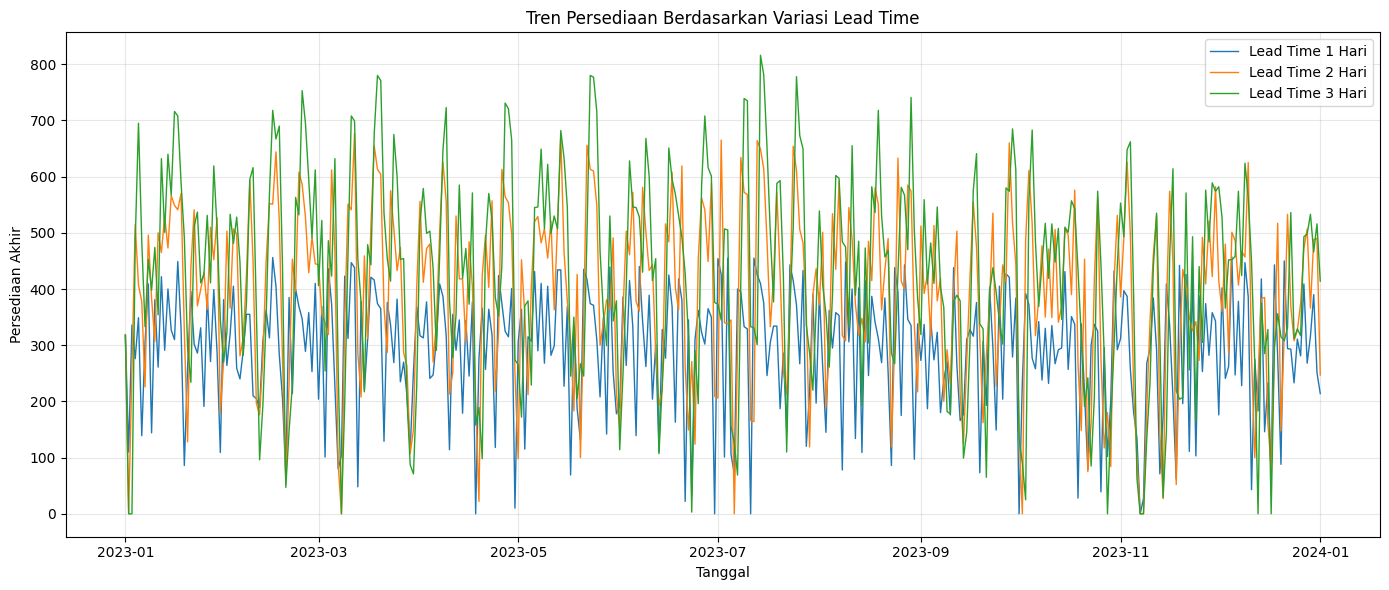

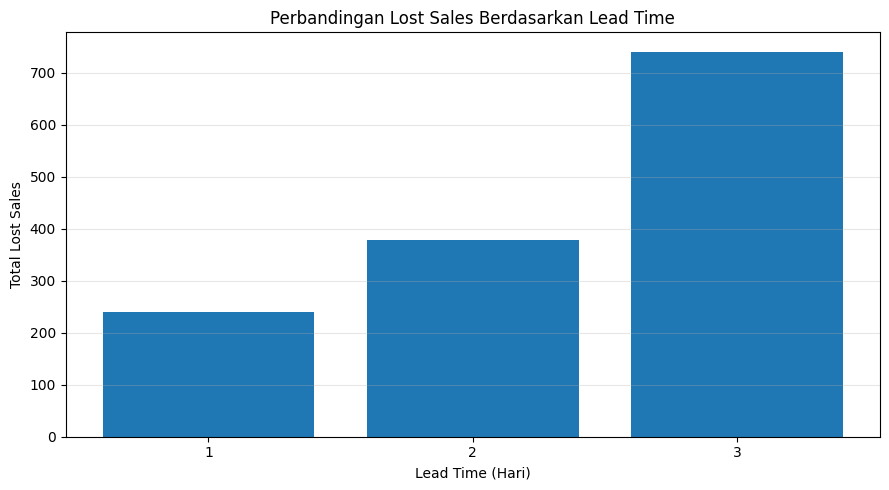

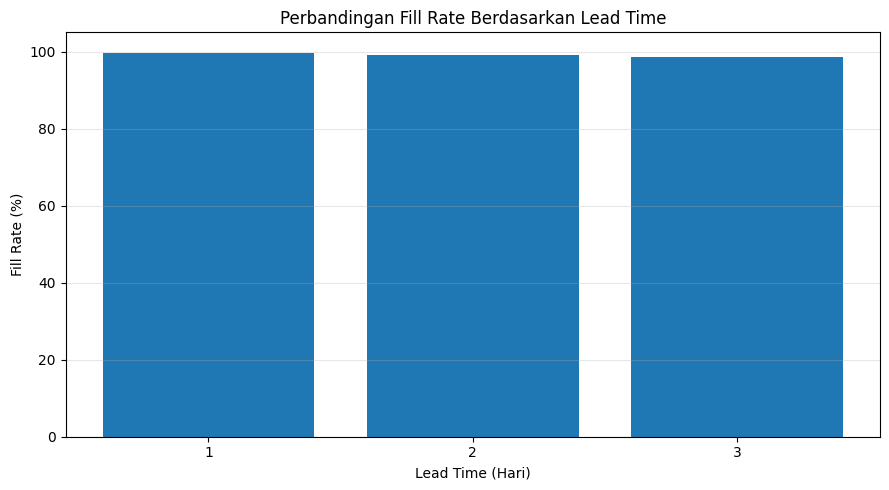

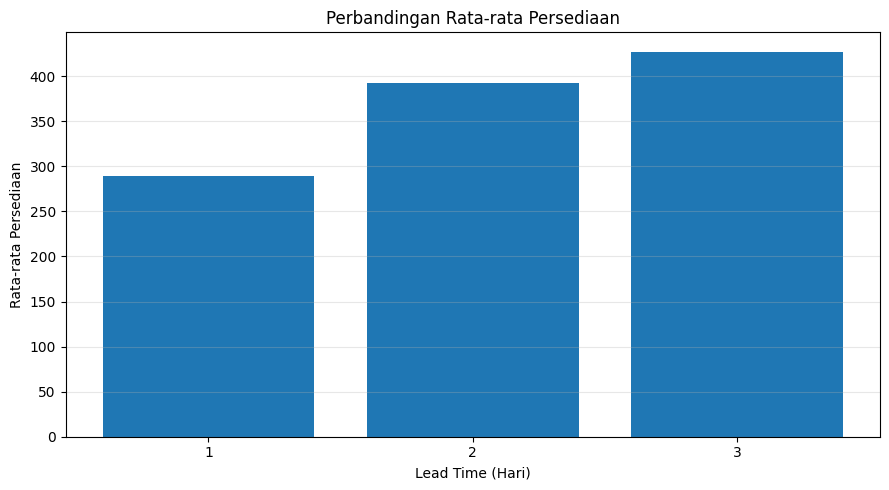

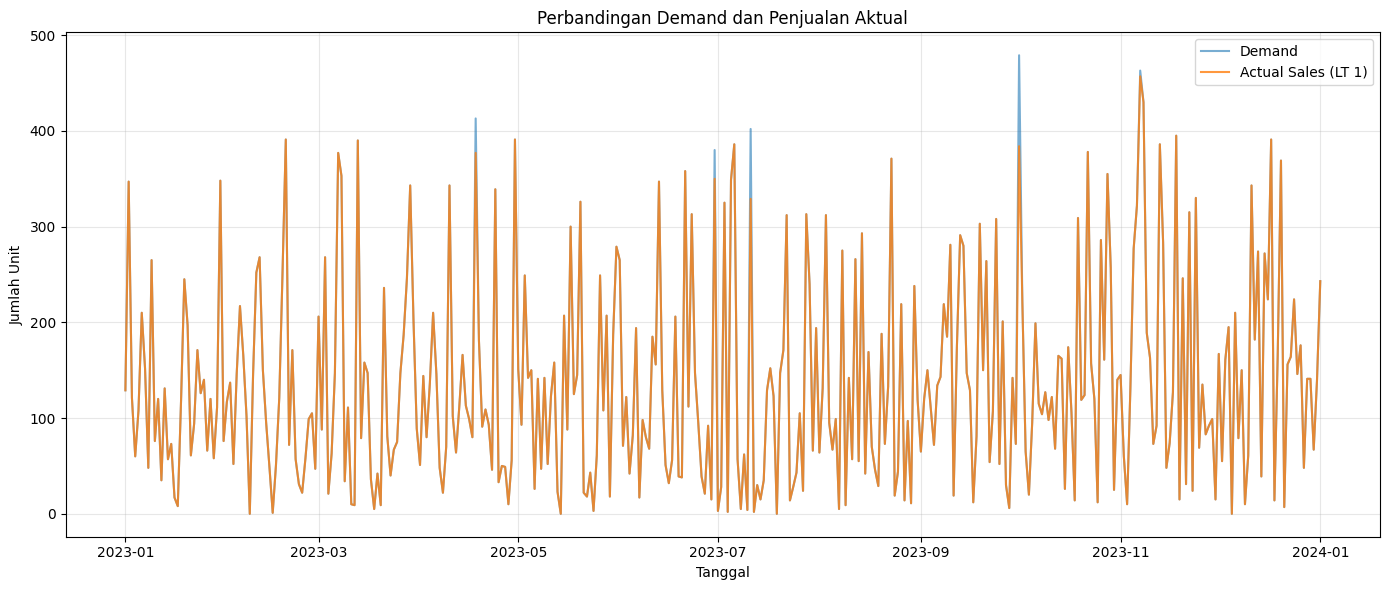

SELURUH VISUALISASI BERHASIL DIBUAT!


In [15]:
# ============================================================
# VISUALISASI HASIL SIMULASI PERSEDIAAN
# ============================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. TREN PERSEDIAAN SELAMA PERIODE PENGUJIAN
# ------------------------------------------------------------

plt.figure(figsize=(14, 6))

for lead_time, hasil in hasil_simulasi_semua.items():

    plt.plot(
        hasil["Date"],
        hasil["Persediaan_Akhir"],
        label=f"Lead Time {lead_time} Hari",
        linewidth=1
    )

plt.title("Tren Persediaan Berdasarkan Variasi Lead Time")
plt.xlabel("Tanggal")
plt.ylabel("Persediaan Akhir")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. PERBANDINGAN LOST SALES
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    ringkasan_simulasi["Lead_Time"].astype(str),
    ringkasan_simulasi["Lost_Sales"]
)

plt.title("Perbandingan Lost Sales Berdasarkan Lead Time")
plt.xlabel("Lead Time (Hari)")
plt.ylabel("Total Lost Sales")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. PERBANDINGAN FILL RATE
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    ringkasan_simulasi["Lead_Time"].astype(str),
    ringkasan_simulasi["Fill_Rate_Persen"]
)

plt.title("Perbandingan Fill Rate Berdasarkan Lead Time")
plt.xlabel("Lead Time (Hari)")
plt.ylabel("Fill Rate (%)")
plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. RATA-RATA PERSEDIAAN
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    ringkasan_simulasi["Lead_Time"].astype(str),
    ringkasan_simulasi["Rata_Rata_Persediaan"]
)

plt.title("Perbandingan Rata-rata Persediaan")
plt.xlabel("Lead Time (Hari)")
plt.ylabel("Rata-rata Persediaan")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. PERMINTAAN DAN PENJUALAN
# ------------------------------------------------------------

plt.figure(figsize=(14, 6))

plt.plot(
    data_pengujian["Date"],
    data_pengujian["Units Sold"],
    label="Demand",
    alpha=0.6
)

plt.plot(
    hasil_simulasi_semua[1]["Date"],
    hasil_simulasi_semua[1]["Actual_Sales"],
    label="Actual Sales (LT 1)",
    alpha=0.8
)

plt.title("Perbandingan Demand dan Penjualan Aktual")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah Unit")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("SELURUH VISUALISASI BERHASIL DIBUAT!")

In [14]:
# ============================================================
# VALIDASI KESEIMBANGAN HASIL SIMULASI
# ============================================================

print("=" * 70)
print("VALIDASI KESEIMBANGAN PERSEDIAAN")
print("=" * 70)

for lead_time, hasil in hasil_simulasi_semua.items():

    # Validasi keseimbangan persediaan
    saldo_hitung = (
        hasil["Persediaan_Awal_Hari"]
        + hasil["Arrival_Quantity"]
        - hasil["Actual_Sales"]
    )

    error_saldo = (
        saldo_hitung - hasil["Persediaan_Akhir"]
    ).abs().sum()

    # Validasi total demand
    error_demand = (
        hasil["Demand"].sum()
        - hasil["Actual_Sales"].sum()
        - hasil["Lost_Sales"].sum()
    )

    # Validasi persediaan tersedia
    error_tersedia = (
        hasil["Persediaan_Awal_Hari"]
        + hasil["Arrival_Quantity"]
        - hasil["Persediaan_Tersedia"]
    ).abs().sum()

    # Pemeriksaan nilai negatif
    kolom_numerik = [
        "Persediaan_Awal_Hari",
        "Arrival_Quantity",
        "Persediaan_Tersedia",
        "Actual_Sales",
        "Lost_Sales",
        "Persediaan_Akhir",
        "Outstanding_Order",
        "Order_Quantity"
    ]

    ada_nilai_negatif = (
        hasil[kolom_numerik] < 0
    ).any().any()

    print(f"\n[LEAD TIME {lead_time} HARI]")
    print("-" * 70)

    print(
        "Jumlah data 366 hari:",
        "LULUS" if len(hasil) == 366 else "GAGAL"
    )

    print(
        "Keseimbangan persediaan:",
        "LULUS" if error_saldo == 0 else "GAGAL",
        "| Error:", error_saldo
    )

    print(
        "Keseimbangan total demand:",
        "LULUS" if error_demand == 0 else "GAGAL",
        "| Error:", error_demand
    )

    print(
        "Keseimbangan persediaan tersedia:",
        "LULUS" if error_tersedia == 0 else "GAGAL",
        "| Error:", error_tersedia
    )

    print(
        "Tidak ada nilai negatif:",
        "GAGAL" if ada_nilai_negatif else "LULUS"
    )

    assert len(hasil) == 366
    assert error_saldo == 0
    assert error_demand == 0
    assert error_tersedia == 0
    assert not ada_nilai_negatif

print("\nSELURUH VALIDASI KESEIMBANGAN SELESAI!")

VALIDASI KESEIMBANGAN PERSEDIAAN

[LEAD TIME 1 HARI]
----------------------------------------------------------------------
Jumlah data 366 hari: LULUS
Keseimbangan persediaan: LULUS | Error: 0
Keseimbangan total demand: LULUS | Error: 0
Keseimbangan persediaan tersedia: LULUS | Error: 0
Tidak ada nilai negatif: LULUS

[LEAD TIME 2 HARI]
----------------------------------------------------------------------
Jumlah data 366 hari: LULUS
Keseimbangan persediaan: LULUS | Error: 0
Keseimbangan total demand: LULUS | Error: 0
Keseimbangan persediaan tersedia: LULUS | Error: 0
Tidak ada nilai negatif: LULUS

[LEAD TIME 3 HARI]
----------------------------------------------------------------------
Jumlah data 366 hari: LULUS
Keseimbangan persediaan: LULUS | Error: 0
Keseimbangan total demand: LULUS | Error: 0
Keseimbangan persediaan tersedia: LULUS | Error: 0
Tidak ada nilai negatif: LULUS

SELURUH VALIDASI KESEIMBANGAN SELESAI!


In [13]:
print("Pemeriksaan Lead Time 3 Hari")
print("=" * 45)

hasil_lt3 = ringkasan_simulasi[
    ringkasan_simulasi["Lead_Time"] == 3
]

display(hasil_lt3)

Pemeriksaan Lead Time 3 Hari


,Lead_Time,Total_Demand,Total_Sales,Lost_Sales,Fill_Rate_Persen,Rata_Rata_Persediaan,Hari_Stockout,Total_Order,Total_Arrival
2,3,49868,49127,741,98.514077,427.368852,8,49543,49094


In [12]:
# ============================================================
# RINGKASAN KINERJA SIMULASI
# ============================================================

hasil_ringkasan = []

for lead_time, hasil in hasil_simulasi_semua.items():

    total_demand = hasil["Demand"].sum()
    total_sales = hasil["Actual_Sales"].sum()
    total_lost_sales = hasil["Lost_Sales"].sum()

    fill_rate = (
        total_sales / total_demand * 100
        if total_demand > 0 else 0
    )

    rata_rata_persediaan = (
        hasil["Persediaan_Akhir"].mean()
    )

    # Hari stockout dihitung berdasarkan adanya lost sales
    hari_stockout = (
        hasil["Lost_Sales"] > 0
    ).sum()

    hasil_ringkasan.append({
        "Lead_Time": lead_time,
        "Total_Demand": total_demand,
        "Total_Sales": total_sales,
        "Lost_Sales": total_lost_sales,
        "Fill_Rate_Persen": fill_rate,
        "Rata_Rata_Persediaan": rata_rata_persediaan,
        "Hari_Stockout": hari_stockout,
        "Total_Order": hasil["Order_Quantity"].sum(),
        "Total_Arrival": hasil["Arrival_Quantity"].sum()
    })

ringkasan_simulasi = pd.DataFrame(hasil_ringkasan)

print("=" * 100)
print("RINGKASAN KINERJA SIMULASI PERSEDIAAN RETAIL")
print("=" * 100)

display(ringkasan_simulasi.round(2))

RINGKASAN KINERJA SIMULASI PERSEDIAAN RETAIL


,Lead_Time,Total_Demand,Total_Sales,Lost_Sales,Fill_Rate_Persen,Rata_Rata_Persediaan,Hari_Stockout,Total_Order,Total_Arrival
0,1,49868,49628,240,99.52,289.48,5,49638,49395
1,2,49868,49490,378,99.24,392.97,6,49739,49290
2,3,49868,49127,741,98.51,427.37,8,49543,49094


In [10]:
# ============================================================
# MENJALANKAN SIMULASI PENGUJIAN
# ============================================================

hasil_simulasi_semua = {}

for _, parameter in parameter_kalibrasi.iterrows():

    lead_time = int(parameter["Lead_Time"])
    reorder_point = int(parameter["Reorder_Point"])
    target_persediaan = int(parameter["Target_Persediaan"])

    hasil = jalankan_simulasi(
        data=data_pengujian,
        lead_time=lead_time,
        reorder_point=reorder_point,
        target_persediaan=target_persediaan
    )

    hasil_simulasi_semua[lead_time] = hasil

    print("=" * 65)
    print(f"HASIL SIMULASI LEAD TIME {lead_time} HARI")
    print("=" * 65)

    print("Jumlah hari       :", len(hasil))
    print("Total demand      :", hasil["Demand"].sum())
    print("Total penjualan   :", hasil["Actual_Sales"].sum())
    print("Total lost sales  :", hasil["Lost_Sales"].sum())
    print("Total pemesanan   :", hasil["Order_Quantity"].sum())
    print("Total kedatangan  :", hasil["Arrival_Quantity"].sum())

print("\nSEMUA SIMULASI BERHASIL DIJALANKAN!")

HASIL SIMULASI LEAD TIME 1 HARI
Jumlah hari       : 366
Total demand      : 49868
Total penjualan   : 49628
Total lost sales  : 240
Total pemesanan   : 49638
Total kedatangan  : 49395
HASIL SIMULASI LEAD TIME 2 HARI
Jumlah hari       : 366
Total demand      : 49868
Total penjualan   : 49490
Total lost sales  : 378
Total pemesanan   : 49739
Total kedatangan  : 49290
HASIL SIMULASI LEAD TIME 3 HARI
Jumlah hari       : 366
Total demand      : 49868
Total penjualan   : 49127
Total lost sales  : 741
Total pemesanan   : 49543
Total kedatangan  : 49094

SEMUA SIMULASI BERHASIL DIJALANKAN!


In [9]:
# ============================================================
# MESIN SIMULASI DINAMIK PERSEDIAAN RETAIL
# ============================================================

def jalankan_simulasi(data, lead_time, reorder_point, target_persediaan):

    data = data.copy().reset_index(drop=True)

    # Kondisi awal persediaan
    persediaan_awal = int(data.loc[0, "Inventory Level"])

    # Pipeline awal diasumsikan kosong
    pipeline = []

    hasil = []

    for index, baris in data.iterrows():

        tanggal = baris["Date"]
        demand = int(baris["Units Sold"])

        persediaan_awal_hari = persediaan_awal

        # ----------------------------------------------------
        # 1. PENERIMAAN PESANAN YANG TELAH JATUH TEMPO
        # ----------------------------------------------------

        arrival_quantity = sum(
            pesanan["quantity"]
            for pesanan in pipeline
            if pesanan["arrival_day"] == index
        )

        # Menghapus pesanan yang sudah diterima
        pipeline = [
            pesanan for pesanan in pipeline
            if pesanan["arrival_day"] != index
        ]

        persediaan_tersedia = (
            persediaan_awal_hari + arrival_quantity
        )

        # ----------------------------------------------------
        # 2. PROSES PENJUALAN
        # ----------------------------------------------------

        actual_sales = min(
            demand,
            persediaan_tersedia
        )

        lost_sales = demand - actual_sales

        persediaan_akhir = (
            persediaan_tersedia - actual_sales
        )

        # ----------------------------------------------------
        # 3. MENGHITUNG POSISI PERSEDIAAN
        # ----------------------------------------------------

        outstanding_order = sum(
            pesanan["quantity"]
            for pesanan in pipeline
        )

        inventory_position = (
            persediaan_akhir + outstanding_order
        )

        # ----------------------------------------------------
        # 4. KEBIJAKAN PEMESANAN ULANG
        # ----------------------------------------------------

        order_quantity = 0

        if inventory_position <= reorder_point:

            order_quantity = max(
                0,
                target_persediaan - inventory_position
            )

            if order_quantity > 0:

                pipeline.append({
                    "quantity": order_quantity,
                    "arrival_day": index + lead_time
                })

        # ----------------------------------------------------
        # 5. MENYIMPAN HASIL SIMULASI HARIAN
        # ----------------------------------------------------

        hasil.append({

            "Date": tanggal,
            "Demand": demand,
            "Persediaan_Awal_Hari": persediaan_awal_hari,
            "Arrival_Quantity": arrival_quantity,
            "Persediaan_Tersedia": persediaan_tersedia,
            "Actual_Sales": actual_sales,
            "Lost_Sales": lost_sales,
            "Persediaan_Akhir": persediaan_akhir,
            "Outstanding_Order": outstanding_order,
            "Inventory_Position": inventory_position,
            "Order_Quantity": order_quantity,
            "Lead_Time": lead_time

        })

        # Persediaan akhir menjadi persediaan awal hari berikutnya
        persediaan_awal = persediaan_akhir

    hasil_simulasi = pd.DataFrame(hasil)

    return hasil_simulasi


print("=" * 65)
print("MESIN SIMULASI BERHASIL DIBUAT")
print("=" * 65)

print("Fungsi simulasi       : jalankan_simulasi()")
print("Jumlah variasi LT     :", len(daftar_lead_time))
print("Lead time             :", daftar_lead_time)
print("Kondisi awal          : Persediaan aktual hari pertama pengujian")
print("Pipeline awal         : 0")

MESIN SIMULASI BERHASIL DIBUAT
Fungsi simulasi       : jalankan_simulasi()
Jumlah variasi LT     : 3
Lead time             : [1, 2, 3]
Kondisi awal          : Persediaan aktual hari pertama pengujian
Pipeline awal         : 0


In [8]:
# ============================================================
# MENYIMPAN PARAMETER HASIL KALIBRASI
# ============================================================

parameter_kalibrasi.to_csv(
    "parameter_kalibrasi.csv",
    index=False
)

print("Parameter kalibrasi berhasil disimpan!")

display(parameter_kalibrasi)

Parameter kalibrasi berhasil disimpan!


,Lead_Time,Rata_Rata_Demand_Harian,Rata_Rata_Demand_Lead_Time,Safety_Stock,Reorder_Point,Target_Persediaan
0,1,135.427397,135.427397,186,322,457
1,2,135.427397,270.876374,289,560,696
2,3,135.427397,406.669421,320,727,863


In [7]:
# ============================================================
# KALIBRASI PARAMETER KEBIJAKAN PERSEDIAAN
# ============================================================

tingkat_persentil = 0.95
daftar_lead_time = [1, 2, 3]

rata_demand = data_kalibrasi["Units Sold"].mean()

hasil_parameter = []

for lead_time in daftar_lead_time:

    # Permintaan kumulatif selama lead time
    rolling_demand = (
        data_kalibrasi["Units Sold"]
        .rolling(window=lead_time)
        .sum()
        .dropna()
    )

    # Rata-rata demand aktual selama lead time
    rata_demand_lt = rolling_demand.mean()

    # Reorder Point berdasarkan persentil ke-95
    reorder_point = math.ceil(
        rolling_demand.quantile(tingkat_persentil)
    )

    # Safety Stock
    safety_stock = (
        reorder_point - math.ceil(rata_demand_lt)
    )

    # Target Persediaan
    target_persediaan = math.ceil(
        rolling_demand.quantile(tingkat_persentil)
        + rata_demand
    )

    hasil_parameter.append({
        "Lead_Time": lead_time,
        "Rata_Rata_Demand_Harian": rata_demand,
        "Rata_Rata_Demand_Lead_Time": rata_demand_lt,
        "Safety_Stock": safety_stock,
        "Reorder_Point": reorder_point,
        "Target_Persediaan": target_persediaan
    })

parameter_kalibrasi = pd.DataFrame(hasil_parameter)

print("=" * 75)
print("HASIL KALIBRASI PARAMETER PERSEDIAAN")
print("=" * 75)

display(parameter_kalibrasi.round(2))

HASIL KALIBRASI PARAMETER PERSEDIAAN


,Lead_Time,Rata_Rata_Demand_Harian,Rata_Rata_Demand_Lead_Time,Safety_Stock,Reorder_Point,Target_Persediaan
0,1,135.43,135.43,186,322,457
1,2,135.43,270.88,289,560,696
2,3,135.43,406.67,320,727,863


In [5]:
# ============================================================
# PEMISAHAN DATA KALIBRASI DAN DATA PENGUJIAN
# ============================================================

# Data kalibrasi: tahun 2022
data_kalibrasi = data_objek[
    (data_objek["Date"] >= "2022-01-01") &
    (data_objek["Date"] <= "2022-12-31")
].copy().reset_index(drop=True)

# Data pengujian: tahun 2023 sampai 1 Januari 2024
data_pengujian = data_objek[
    (data_objek["Date"] >= "2023-01-01") &
    (data_objek["Date"] <= "2024-01-01")
].copy().reset_index(drop=True)

print("=" * 65)
print("PEMISAHAN DATA KALIBRASI DAN PENGUJIAN")
print("=" * 65)

print("\n[1] DATA KALIBRASI")
print("-" * 65)
print("Jumlah observasi :", len(data_kalibrasi))
print("Tanggal awal     :", data_kalibrasi["Date"].min().date())
print("Tanggal akhir    :", data_kalibrasi["Date"].max().date())
print("Rata-rata demand :", round(data_kalibrasi["Units Sold"].mean(), 2))

print("\n[2] DATA PENGUJIAN")
print("-" * 65)
print("Jumlah observasi :", len(data_pengujian))
print("Tanggal awal     :", data_pengujian["Date"].min().date())
print("Tanggal akhir    :", data_pengujian["Date"].max().date())
print("Rata-rata demand :", round(data_pengujian["Units Sold"].mean(), 2))

print("\n[3] PEMERIKSAAN PEMBAGIAN DATA")
print("-" * 65)

assert len(data_kalibrasi) == 365
assert len(data_pengujian) == 366
assert len(data_kalibrasi) + len(data_pengujian) == len(data_objek)

print("Jumlah data kalibrasi + pengujian sesuai :", "LULUS")
print("Jumlah data kalibrasi 365 hari           :", "LULUS")
print("Jumlah data pengujian 366 hari           :", "LULUS")
print("Tidak ada data yang hilang               :", "LULUS")

PEMISAHAN DATA KALIBRASI DAN PENGUJIAN

[1] DATA KALIBRASI
-----------------------------------------------------------------
Jumlah observasi : 365
Tanggal awal     : 2022-01-01
Tanggal akhir    : 2022-12-31
Rata-rata demand : 135.43

[2] DATA PENGUJIAN
-----------------------------------------------------------------
Jumlah observasi : 366
Tanggal awal     : 2023-01-01
Tanggal akhir    : 2024-01-01
Rata-rata demand : 136.25

[3] PEMERIKSAAN PEMBAGIAN DATA
-----------------------------------------------------------------
Jumlah data kalibrasi + pengujian sesuai : LULUS
Jumlah data kalibrasi 365 hari           : LULUS
Jumlah data pengujian 366 hari           : LULUS
Tidak ada data yang hilang               : LULUS


In [4]:
# ============================================================
# VALIDASI DATA DAN PEMILIHAN OBJEK SIMULASI
# ============================================================

# Mengubah kolom Date menjadi format datetime
df["Date"] = pd.to_datetime(df["Date"])

# Mengurutkan data berdasarkan tanggal
df = df.sort_values("Date").reset_index(drop=True)

print("=" * 65)
print("VALIDASI DATASET UTS PEMODELAN DAN SIMULASI")
print("=" * 65)

print("\n[1] INFORMASI DATASET")
print("-" * 65)
print("Jumlah baris             :", len(df))
print("Jumlah kolom             :", len(df.columns))
print("Jumlah tanggal unik      :", df["Date"].nunique())
print("Tanggal awal             :", df["Date"].min().date())
print("Tanggal akhir            :", df["Date"].max().date())
print("Jumlah toko              :", df["Store ID"].nunique())
print("Jumlah produk            :", df["Product ID"].nunique())
print("Data kosong              :", df.isnull().sum().sum())
print("Duplikasi baris          :", df.duplicated().sum())

# Memilih objek simulasi
store_id = "S004"
product_id = "P0020"

data_objek = df[
    (df["Store ID"] == store_id) &
    (df["Product ID"] == product_id)
].copy()

data_objek = data_objek.sort_values("Date").reset_index(drop=True)

print("\n[2] OBJEK SIMULASI")
print("-" * 65)
print("Store ID                 :", store_id)
print("Product ID               :", product_id)
print("Jumlah observasi         :", len(data_objek))
print("Rata-rata penjualan      :", round(data_objek["Units Sold"].mean(), 2))
print("Rata-rata persediaan     :", round(data_objek["Inventory Level"].mean(), 2))
print("Rata-rata pemesanan      :", round(data_objek["Units Ordered"].mean(), 2))

print("\n[3] LIMA DATA PERTAMA OBJEK SIMULASI")
print("-" * 65)
display(data_objek.head())

VALIDASI DATASET UTS PEMODELAN DAN SIMULASI

[1] INFORMASI DATASET
-----------------------------------------------------------------
Jumlah baris             : 73100
Jumlah kolom             : 15
Jumlah tanggal unik      : 731
Tanggal awal             : 2022-01-01
Tanggal akhir            : 2024-01-01
Jumlah toko              : 5
Jumlah produk            : 20
Data kosong              : 0
Duplikasi baris          : 0

[2] OBJEK SIMULASI
-----------------------------------------------------------------
Store ID                 : S004
Product ID               : P0020
Jumlah observasi         : 731
Rata-rata penjualan      : 135.84
Rata-rata persediaan     : 275.11
Rata-rata pemesanan      : 111.16

[3] LIMA DATA PERTAMA OBJEK SIMULASI
-----------------------------------------------------------------


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S004,P0020,Clothing,West,211,68,37,86.27,11.50,20,Snowy,0,9.26,Winter
1,2022-01-02,S004,P0020,Electronics,North,254,84,112,77.15,73.05,15,Sunny,1,74.55,Autumn
2,2022-01-03,S004,P0020,Clothing,East,197,149,134,161.20,95.33,20,Cloudy,0,97.42,Winter
3,2022-01-04,S004,P0020,Groceries,South,364,62,27,68.97,86.86,15,Snowy,0,89.19,Spring
4,2022-01-05,S004,P0020,Toys,South,149,131,42,147.54,23.85,5,Cloudy,0,19.43,Autumn


In [3]:
# ============================================================
# UPLOAD DATASET
# ============================================================

uploaded = files.upload()

nama_file = next(iter(uploaded))

df = pd.read_csv(nama_file)

print("Dataset berhasil dimuat!")
print("Nama file:", nama_file)
print("Ukuran dataset:", df.shape)

display(df.head())

Saving retail_store_inventory.csv to retail_store_inventory.csv
Dataset berhasil dimuat!
Nama file: retail_store_inventory.csv
Ukuran dataset: (73100, 15)


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer


In [1]:
# ============================================================
# UTS PEMODELAN DAN SIMULASI
# MODEL DINAMIK PERSEDIAAN PRODUK RETAIL
# ============================================================

import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt

from google.colab import files
from IPython.display import display

print("Library berhasil diimpor!")

Library berhasil diimpor!
